In [1]:
%pip install kaggle
import kaggle
import string


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token


In [2]:
import os

# Set your Kaggle credentials
os.environ['KAGGLE_USERNAME'] = 'muhammadrafaymalik'
os.environ['KAGGLE_KEY'] = 'b5b06aa18550e95660bb74a122fcf740'

print("Kaggle authentication credentials successfully applied!")


Kaggle authentication credentials successfully applied!


In [3]:
import kaggle

# Tell the Kaggle library to download the retail orders dataset and extract it here
kaggle.api.dataset_download_files('ankitbansal06/retail-orders', path='.', unzip=True)

print("Success! The dataset has been downloaded and extracted.")


Dataset URL: https://www.kaggle.com/datasets/ankitbansal06/retail-orders
Success! The dataset has been downloaded and extracted.


In [4]:
import zipfile

# 1. Specify the name of your zip file
zip_file_name = 'retail-orders.zip'  # Change this if your file has a different name

# 2. Extract all contents into your current folder
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall('.')
    
print(f"Successfully extracted all files from {zip_file_name}!")


FileNotFoundError: [Errno 2] No such file or directory: 'retail-orders.zip'

In [5]:
import os

# Print everything inside your current notebook folder
print(os.listdir('.'))


['#common password breach system.py', '.anaconda', '.conda', '.copilot', '.designer', '.dotnet', '.eclipse', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.kaggle', '.keras', '.p2', '.python_history', '.templateengine', '.vscode', '.vscode-shared', 'ali=2.py', 'app.js', 'AppData', 'Application Data', 'bmic.calculator.py', 'botnet', 'c.py', 'cd', 'chatbot', 'chatbot_64bit', 'chatbot_new', 'Contacts', 'Cookies', 'dd.txt', 'demo.txt', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'envbitch310', 'Favorites', 'getmac', 'gg.py', 'hhh', 'html', 'html viking', 'IND.HTML', 'inde.html', 'index', 'index,html', 'index.html', 'index.htmls', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'main.py', 'man.html', 'Microsoft', 'My Documents', 'my_env', 'name.py', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer000000000000000000

In [6]:
import pandas as pd

# Load the automatically extracted dataset
df = pd.read_csv('orders.csv')

# Look at the first 5 rows and all columns
df.head()


,Order Id,Order Date,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub Category,Product Id,cost price,List Price,Quantity,Discount Percent
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Order Id          9994 non-null   int64
 1   Order Date        9994 non-null   str  
 2   Ship Mode         9993 non-null   str  
 3   Segment           9994 non-null   str  
 4   Country           9994 non-null   str  
 5   City              9994 non-null   str  
 6   State             9994 non-null   str  
 7   Postal Code       9994 non-null   int64
 8   Region            9994 non-null   str  
 9   Category          9994 non-null   str  
 10  Sub Category      9994 non-null   str  
 11  Product Id        9994 non-null   str  
 12  cost price        9994 non-null   int64
 13  List Price        9994 non-null   int64
 14  Quantity          9994 non-null   int64
 15  Discount Percent  9994 non-null   int64
dtypes: int64(6), str(10)
memory usage: 2.2 MB


In [8]:
# Make column names cleaner (e.g., 'Order Id' becomes 'order_id')
df.columns = df.columns.str.lower().str.replace(' ', '_')

# View the new column names
df.columns


Index(['order_id', 'order_date', 'ship_mode', 'segment', 'country', 'city',
       'state', 'postal_code', 'region', 'category', 'sub_category',
       'product_id', 'cost_price', 'list_price', 'quantity',
       'discount_percent'],
      dtype='str')

In [9]:
# Convert order_date to a real date format
df['order_date'] = pd.to_datetime(df['order_date'])

# Verify the change
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          9994 non-null   int64         
 1   order_date        9994 non-null   datetime64[us]
 2   ship_mode         9993 non-null   str           
 3   segment           9994 non-null   str           
 4   country           9994 non-null   str           
 5   city              9994 non-null   str           
 6   state             9994 non-null   str           
 7   postal_code       9994 non-null   int64         
 8   region            9994 non-null   str           
 9   category          9994 non-null   str           
 10  sub_category      9994 non-null   str           
 11  product_id        9994 non-null   str           
 12  cost_price        9994 non-null   int64         
 13  list_price        9994 non-null   int64         
 14  quantity          9994 non-null   i

In [10]:
# 1. Fix the single missing value in ship_mode by filling it with 'Unknown'
df['ship_mode'] = df['ship_mode'].fillna('Unknown')

# 2. Calculate the actual discount amount money saved per unit
# (list_price * discount_percent / 100)
df['discount_amount'] = df['list_price'] * (df['discount_percent'] / 100)

# 3. Calculate the actual selling price after discount
df['selling_price'] = df['list_price'] - df['discount_amount']

# 4. Calculate total revenue for the order (selling_price * quantity)
df['total_revenue'] = df['selling_price'] * df['quantity']

# 5. Calculate total cost for the order (cost_price * quantity)
df['total_cost'] = df['cost_price'] * df['quantity']

# 6. Calculate total profit earned (total_revenue - total_cost)
df['profit'] = df['total_revenue'] - df['total_cost']

# Preview our brand new metrics!
df[['category', 'quantity', 'list_price', 'discount_percent', 'selling_price', 'profit']].head()


,category,quantity,list_price,discount_percent,selling_price,profit
0,Furniture,2,260,2,254.8,29.6
1,Furniture,3,730,3,708.1,324.3
2,Office Supplies,2,10,5,9.5,-1.0
3,Furniture,5,960,2,940.8,804.0
4,Office Supplies,2,20,5,19.0,-2.0


In [11]:
# Group by sub-category to see where the losses are happening
sub_profit = df.groupby('sub_category')['profit'].sum().reset_index()
sub_profit = sub_profit.sort_values(by='profit', ascending=True) # Ascending shows losses first
sub_profit.head(5)


,sub_category,profit
8,Fasteners,458.6
10,Labels,4188.8
7,Envelopes,6109.7
2,Art,10412.2
15,Supplies,14402.5


In [12]:
# Check the average discount percent for each sub-category
discount_analysis = df.groupby('sub_category')['discount_percent'].mean().reset_index()
discount_analysis.sort_values(by='discount_percent', ascending=False).head(5)


,sub_category,discount_percent
16,Tables,3.589342
15,Supplies,3.557895
7,Envelopes,3.531496
12,Paper,3.521898
6,Copiers,3.514706


C:\Users\Rafay\AppData\Local\Temp\ipykernel_1044\434412874.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='profit', y='sub_category', data=plot_data, palette='coolwarm')


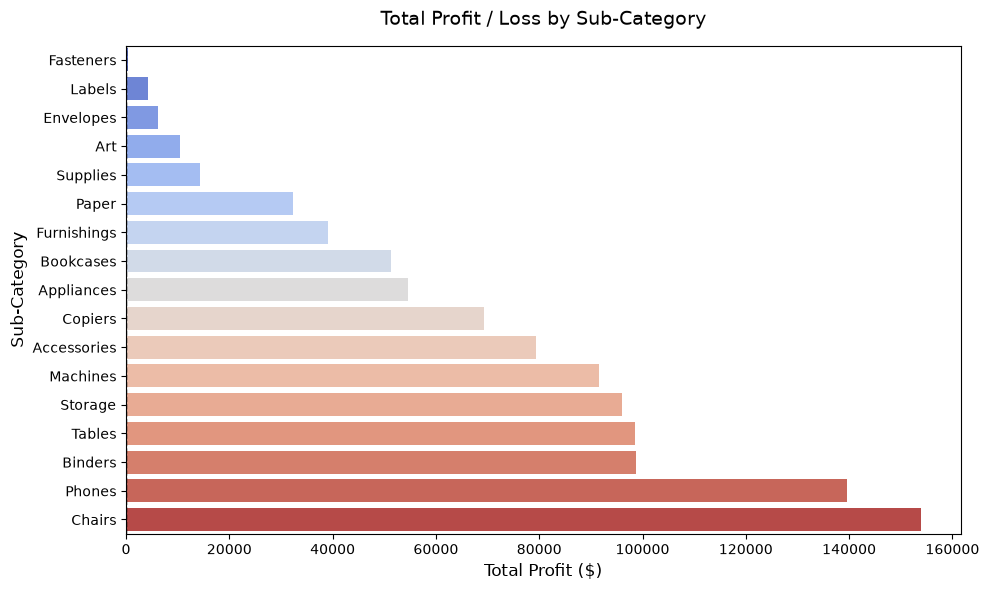

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data by grouping sub_categories by total profit
plot_data = df.groupby('sub_category')['profit'].sum().reset_index().sort_values(by='profit')

# Create a clean horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='profit', y='sub_category', data=plot_data, palette='coolwarm')

# Customize chart design
plt.title('Total Profit / Loss by Sub-Category', fontsize=14, pad=15)
plt.xlabel('Total Profit ($)', fontsize=12)
plt.ylabel('Sub-Category', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1) # Visual divider for losses
plt.tight_layout()

# Render plot in Jupyter
plt.show()


In [15]:
# Group by year-month and sum the revenue
df['year_month'] = df['order_date'].dt.to_period('M')
monthly_sales = df.groupby('year_month')['total_revenue'].sum().reset_index()
monthly_sales


,year_month,total_revenue
0,2022-01,437431.3
1,2022-02,444011.1
2,2022-03,394105.2
3,2022-04,476400.9
4,2022-05,413625.5
5,2022-06,465300.3
6,2022-07,375278.4
7,2022-08,534562.4
8,2022-09,433887.0
9,2022-10,601707.8


In [16]:
# Save to an Excel file without the index row
df.to_excel('cleaned_retail_orders.xlsx', index=False)
print("Success! 'cleaned_retail_orders.xlsx' has been created in your folder.")


Success! 'cleaned_retail_orders.xlsx' has been created in your folder.
